In [1]:
from sklearn import tree
from sklearn.preprocessing import LabelEncoder
import pandas as pd
import random

data = pd.read_excel('data_for_train.xlsx') 
for i in range(0,4):
    data = data.drop(['Unnamed: '+str(i)], axis=1)
for i in range(12,18):
    data = data.drop(['Unnamed: '+str(i)], axis=1)
# with open("datafile.txt", "rb") as f:
#     data = f.read().split('\n')
# random.shuffle(data)

# train_data = data[:50]
# test_data = data[50:]

In [2]:
len(data)

3000

In [3]:
data.head()

,model,result_check_user_location,result_check_model,result_check_MAC_address,result_check_MAC_address_exists,result_check_device_location,result_check_device_location_exists,result
0,non-portable,True,True,False,True,True,True,Allow with condition
1,portable,True,True,True,True,False,False,Allow
2,portable,True,True,True,True,False,False,Allow
3,non-portable,True,True,False,True,True,True,Allow with condition
4,portable,True,True,True,True,False,False,Allow


In [4]:
data.model = data.model.astype('category')
data.result = data.result.astype('category')

In [5]:
data.dtypes

model                                  category
result_check_user_location                 bool
result_check_model                         bool
result_check_MAC_address                   bool
result_check_MAC_address_exists            bool
result_check_device_location               bool
result_check_device_location_exists        bool
result                                 category
dtype: object

In [6]:
data = data.apply(LabelEncoder().fit_transform)

In [7]:
data

,model,result_check_user_location,result_check_model,result_check_MAC_address,result_check_MAC_address_exists,result_check_device_location,result_check_device_location_exists,result
0,0,1,1,0,1,1,1,1
1,1,1,1,1,1,0,0,0
2,1,1,1,1,1,0,0,0
3,0,1,1,0,1,1,1,1
4,1,1,1,1,1,0,0,0
...,...,...,...,...,...,...,...,...
2995,1,1,0,0,0,1,1,2
2996,0,0,0,0,1,0,1,2
2997,0,1,1,0,1,0,1,1
2998,1,1,0,0,0,0,1,2


In [8]:
y = data.drop_duplicates(keep='first')
y = y.reset_index()
data = y
y

,index,model,result_check_user_location,result_check_model,result_check_MAC_address,result_check_MAC_address_exists,result_check_device_location,result_check_device_location_exists,result
0,0,0,1,1,0,1,1,1,1
1,1,1,1,1,1,1,0,0,0
2,7,0,1,1,1,1,1,1,0
3,13,0,1,0,0,0,0,0,2
4,16,1,0,1,1,1,0,0,2
5,56,1,1,0,0,0,1,1,2
6,66,1,1,1,0,0,0,1,2
7,68,0,1,0,0,1,0,1,2
8,70,1,1,1,0,0,1,1,2
9,76,0,1,1,0,1,0,1,1


In [9]:
import numpy as np
ind = np.random.rand(len(data)) < 0.8

In [10]:
train = data[ind]
test = data[~ind]

In [11]:
label = train.result
train = train.drop(['result'], axis=1)

In [12]:
tlabel = test.result
test = test.drop(['result'], axis=1)

In [13]:
truelabel = pd.DataFrame(tlabel)
truelabel = truelabel.reset_index()

In [14]:
tlabel

11    2
21    2
22    2
Name: result, dtype: int64

In [15]:

clf = tree.DecisionTreeClassifier()
clf = clf.fit(train,label )

In [16]:
x = clf.predict(test)

In [17]:
x

array([1, 2, 2])

In [18]:
result_label = pd.DataFrame(columns = ['result'])
result_label.result = x

In [19]:
result_label

,result
0,1
1,2
2,2


[Text(167.4, 190.26, 'X[0] <= 10.0\ngini = 0.351\nsamples = 24\nvalue = [2, 3, 19]'),
 Text(83.7, 135.9, 'X[4] <= 0.5\ngini = 0.444\nsamples = 3\nvalue = [2, 1, 0]'),
 Text(41.85, 81.53999999999999, 'gini = 0.0\nsamples = 1\nvalue = [0, 1, 0]'),
 Text(125.55000000000001, 81.53999999999999, 'gini = 0.0\nsamples = 2\nvalue = [2, 0, 0]'),
 Text(251.10000000000002, 135.9, 'X[0] <= 81.0\ngini = 0.172\nsamples = 21\nvalue = [0, 2, 19]'),
 Text(209.25, 81.53999999999999, 'X[0] <= 73.0\ngini = 0.375\nsamples = 8\nvalue = [0, 2, 6]'),
 Text(167.4, 27.180000000000007, 'gini = 0.0\nsamples = 6\nvalue = [0, 0, 6]'),
 Text(251.10000000000002, 27.180000000000007, 'gini = 0.0\nsamples = 2\nvalue = [0, 2, 0]'),
 Text(292.95, 81.53999999999999, 'gini = 0.0\nsamples = 13\nvalue = [0, 0, 13]')]

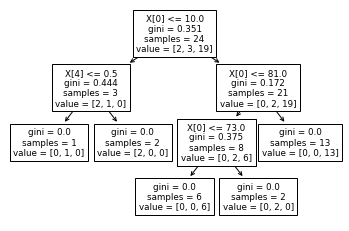

In [20]:
tree.plot_tree(clf.fit(train, label)) 

In [21]:
compare = pd.DataFrame(columns = ['truelabel','predictedlabel'])

compare

In [22]:
compare.truelabel = truelabel.result

In [23]:
compare.predictedlabel = result_label.result

In [24]:
compare

,truelabel,predictedlabel
0,2,1
1,2,2
2,2,2


In [25]:
from sklearn.metrics import accuracy_score
accuracy_score(compare.truelabel, compare.predictedlabel)

0.6666666666666666